## **KLUE-BERT 기반 한국어 영화 리뷰 감정 분석**

1. 사용한 모델과 데이터셋 소개
    -  klue/bert-base
    - NSMC (네이버 영화 리뷰)
2. Tokenizer를 이용한 데이터 전처리
3. 사전학습 모델 Fine-tuning
4. 학습 과정 및 성능 평가
5. 새로운 문장을 직접 입력하여 예측
6. 모델의 문제점 및 개선 방법 분석

In [1]:
import pandas as pd
import numpy as np
import random
import time
import datetime
import os
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
import subprocess

from pathlib import Path
from tqdm.auto import tqdm
from torch.optim import AdamW
from torch.utils.data import TensorDataset, DataLoader, RandomSampler, SequentialSampler
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup, pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [2]:
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cuda


### **1. 사용한 모델과 데이터셋**

In [3]:
MODEL_NAME = 'klue/bert-base'
TRAIN_SAMPLES = 20000
VAL_SAMPLES = 3000
TEST_SAMPLES = 5000
MAX_LEN = 128
BATCH_SIZE = 16
EPOCHS = 5
PATIENCE = 2
LEARNING_RATE = 2e-5

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / 'data'
RESULT_DIR = PROJECT_DIR / 'results'
MODEL_DIR = PROJECT_DIR / 'model'
for path in [DATA_DIR, RESULT_DIR, MODEL_DIR]:
    path.mkdir(parents=True, exist_ok=True)

In [4]:
REPO_DIR = DATA_DIR / 'nsmc'
if not REPO_DIR.exists():
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/e9t/nsmc.git', str(REPO_DIR)], check=True)
else:
    print('이미 저장소가 존재합니다:', REPO_DIR)

for p in REPO_DIR.iterdir():
    print(p.name)

raw
ratings_test.txt
synopses.json
ratings_train.txt
README.md
ratings.txt
code
.git


### **2. Tokenizer를 이용한 데이터 전처리**

In [5]:
train_df = pd.read_csv(REPO_DIR / 'ratings_train.txt', sep='\t')
test_df = pd.read_csv(REPO_DIR / 'ratings_test.txt', sep='\t')
print('원본:', train_df.shape, test_df.shape)
print(train_df.head())
print(train_df['label'].value_counts())

원본: (150000, 3) (50000, 3)
         id                                           document  label
0   9976970                                아 더빙.. 진짜 짜증나네요 목소리      0
1   3819312                  흠...포스터보고 초딩영화줄....오버연기조차 가볍지 않구나      1
2  10265843                                  너무재밓었다그래서보는것을추천한다      0
3   9045019                      교도소 이야기구먼 ..솔직히 재미는 없다..평점 조정      0
4   6483659  사이몬페그의 익살스런 연기가 돋보였던 영화!스파이더맨에서 늙어보이기만 했던 커스틴 ...      1
label
0    75173
1    74827
Name: count, dtype: int64


In [6]:
# 결측치 및 중복 리뷰 제거
def clean_data(df):
    df = df[['document', 'label']].dropna().copy()
    df['document'] = df['document'].astype(str).str.strip()
    df = df[df['document'].str.len() > 0]
    df = df.drop_duplicates(subset=['document']).reset_index(drop=True)
    df['label'] = df['label'].astype(int)

    return df

In [7]:
train_df = clean_data(train_df)
test_df = clean_data(test_df)
# 원본 train과 test 사이에 겹치는 리뷰가 있으면 테스트에서 제거
# 테스트 정보를 학습에 사용하지 않도록 원본 train을 그대로 유지
# 분리 후 같은 문장이 서로 다른 split에 들어가는 것을 방지
train_pool, validation_pool = train_test_split(
    train_df, test_size=0.15, random_state=SEED, stratify=train_df['label']
)
train = train_pool.sample(n=min(TRAIN_SAMPLES, len(train_pool)), random_state=SEED).reset_index(drop=True)
validation = validation_pool.sample(n=min(VAL_SAMPLES, len(validation_pool)), random_state=SEED).reset_index(drop=True)
test_pool = test_df[~test_df['document'].isin(train_df['document'])].copy()
test = test_pool.sample(n=min(TEST_SAMPLES, len(test_pool)), random_state=SEED).reset_index(drop=True)
print('train:', train.shape, 'validation:', validation.shape, 'test:', test.shape)
print(train['label'].value_counts())
print('샘플:', train.iloc[0].to_dict())

train: (20000, 2) validation: (3000, 2) test: (5000, 2)
label
0    10014
1     9986
Name: count, dtype: int64
샘플: {'document': '현재 시네마테크에서 하고 있는 영화.. 놓치면 후회합니다. 바바라 스탠윅&게리 쿠퍼의 조합은 정말 완벽 그 자체다. 빌리 와일더의 위트있는 각본 역시 가히 최고.. 하지만 무엇보다 이 영화는 바바라 스탠윅의 매력에 있다.', 'label': 1}


- 정답은 리뷰 하나당 **부정(0) 또는 긍정(1)** 중 하나
- 모델은 두 개의 logits를 출력하고 **Softmax**로 두 감정 확률을 계산
- `[CLS]`, `[SEP]`, `[PAD]`와 `attention_mask`를 확인

In [8]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print('Tokenizer:', type(tokenizer).__name__)
print('CLS:', tokenizer.cls_token, tokenizer.cls_token_id)
print('SEP:', tokenizer.sep_token, tokenizer.sep_token_id)
print('PAD:', tokenizer.pad_token, tokenizer.pad_token_id)
print('MASK:', tokenizer.mask_token, tokenizer.mask_token_id)

sample_text = train.iloc[0]['document']
sample = tokenizer(sample_text, truncation=True, max_length=32, padding='max_length', return_tensors='pt')
print('문장:', sample_text)
print('input_ids:', sample['input_ids'])
print('tokens:', tokenizer.convert_ids_to_tokens(sample['input_ids'][0]))
print('attention_mask:', sample['attention_mask'])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Tokenizer: BertTokenizerFast
CLS: [CLS] 2
SEP: [SEP] 3
PAD: [PAD] 0
MASK: [MASK] 4
문장: 현재 시네마테크에서 하고 있는 영화.. 놓치면 후회합니다. 바바라 스탠윅&게리 쿠퍼의 조합은 정말 완벽 그 자체다. 빌리 와일더의 위트있는 각본 역시 가히 최고.. 하지만 무엇보다 이 영화는 바바라 스탠윅의 매력에 있다.
input_ids: tensor([[    2,  3738, 17831,  8055, 27135,  6159,  1513,  2259,  3771,    18,
            18,  8043,  2460,  7977, 11800,    18, 28129,  2181,     1,    10,
         25222,  1738,  2712,  2079,  4936,  2073,  3944,  5537,   636,  4029,
          2062,     3]])
tokens: ['[CLS]', '현재', '시네마', '##테크', '##에서', '하고', '있', '##는', '영화', '.', '.', '놓치', '##면', '후회', '##합니다', '.', '바바', '##라', '[UNK]', '&', '게리', '쿠', '##퍼', '##의', '조합', '##은', '정말', '완벽', '그', '자체', '##다', '[SEP]']
attention_mask: tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1, 1, 1, 1, 1]])


In [9]:
def encode_texts(texts, labels, tokenizer, max_len=MAX_LEN):
    encoded = tokenizer(
        [str(x) for x in texts],
        add_special_tokens=True,
        truncation=True,
        max_length=max_len,
        return_tensors='pt',
        padding='max_length'
    )

    return encoded['input_ids'], encoded['attention_mask'], torch.tensor(list(labels), dtype=torch.long)

In [10]:
train_inputs, train_masks, train_labels = encode_texts(train['document'], train['label'], tokenizer)
validation_inputs, validation_masks, validation_labels = encode_texts(validation['document'], validation['label'], tokenizer)
test_inputs, test_masks, test_labels = encode_texts(test['document'], test['label'], tokenizer)
print('input_ids:', train_inputs.shape)
print('attention_mask:', train_masks.shape)
print('labels:', train_labels.shape)

input_ids: torch.Size([20000, 128])
attention_mask: torch.Size([20000, 128])
labels: torch.Size([20000])


In [11]:
train_data = TensorDataset(train_inputs, train_masks, train_labels)
validation_data = TensorDataset(validation_inputs, validation_masks, validation_labels)
test_data = TensorDataset(test_inputs, test_masks, test_labels)

train_dataloader = DataLoader(train_data, sampler=RandomSampler(train_data), batch_size=BATCH_SIZE)
validation_dataloader = DataLoader(validation_data, sampler=SequentialSampler(validation_data), batch_size=BATCH_SIZE)
test_dataloader = DataLoader(test_data, sampler=SequentialSampler(test_data), batch_size=BATCH_SIZE)

batch = next(iter(train_dataloader))
print('input_ids:', batch[0].shape, 'mask:', batch[1].shape, 'labels:', batch[2].shape)

input_ids: torch.Size([16, 128]) mask: torch.Size([16, 128]) labels: torch.Size([16])


#### KLUE-BERT Binary Classification
문장 → Tokenizer → BERT Encoder → Classification Head → 2개 logits → Softmax → 부정/긍정 확률

In [12]:
label_dict = {0: '부정', 1: '긍정'}
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=label_dict,
    label2id={'부정': 0, '긍정': 1},
    problem_type='single_label_classification'
)

model.to(DEVICE)
print(type(model).__name__, model.config.num_labels)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at klue/bert-base and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


BertForSequenceClassification 2


### 3. **사전학습 모델 Fine-Tuning**

In [13]:
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
total_steps = len(train_dataloader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(total_steps * 0.1),
    num_training_steps=total_steps
)
print('전체 최대 학습 step:', total_steps)

전체 최대 학습 step: 6250


In [14]:
def format_time(elapsed):
    return str(datetime.timedelta(seconds=int(round(elapsed))))

def binary_metrics(logits, labels):
    probs = F.softmax(torch.as_tensor(logits), dim=1).numpy()
    y_true = np.asarray(labels)
    y_pred = np.argmax(probs, axis=1)

    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0)
    }

def evaluate(model, dataloader, device):
    model.eval()
    all_logits, all_labels = [], []
    total_loss = 0.0
    for batch in tqdm(dataloader, leave=False):
        input_ids, attention_mask, labels = [x.to(device) for x in batch]

        with torch.inference_mode():
            outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)

        total_loss += outputs.loss.item()
        all_logits.append(outputs.logits.cpu())
        all_labels.append(labels.cpu())

    logits = torch.cat(all_logits).numpy()
    labels = torch.cat(all_labels).numpy()
    metrics = binary_metrics(logits, labels)
    metrics['loss'] = total_loss / len(dataloader)

    return metrics, logits, labels

### 4. 학습 과정 및 성능 평가

In [15]:
history = []
best_f1 = -1.0
wait = 0
BEST_MODEL_PATH = MODEL_DIR / 'KLUE_BERT_movie_best.pt'

for epoch in range(EPOCHS):
    print(f'\n======== Epoch {epoch + 1} / {EPOCHS} ========')
    start = time.time()
    model.train()
    total_loss = 0.0

    for batch in tqdm(train_dataloader):
        input_ids, attention_mask, labels = [x.to(DEVICE) for x in batch]
        optimizer.zero_grad(set_to_none=True)
        outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        total_loss += loss.item()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()

    avg_loss = total_loss / len(train_dataloader)
    valid_metrics, _, _ = evaluate(model, validation_dataloader, DEVICE)
    record = {'epoch': epoch + 1, 'train_loss': avg_loss, **{'val_' + k: v for k, v in valid_metrics.items()}}
    history.append(record)
    print(f'Train Loss: {avg_loss:.4f} | Val Loss: {valid_metrics["loss"]:.4f}')
    print(f'Val Accuracy: {valid_metrics["accuracy"]:.4f} | Precision: {valid_metrics["precision"]:.4f} | Recall: {valid_metrics["recall"]:.4f} | F1: {valid_metrics["f1"]:.4f}')
    print('Time:', format_time(time.time() - start))

    if valid_metrics['f1'] > best_f1:
        best_f1 = valid_metrics['f1']
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        wait = 0
        print('검증 F1 개선: 최고 모델 저장', BEST_MODEL_PATH)
    else:
        wait += 1
        print(f'개선 없음: {wait}/{PATIENCE}')
        if wait >= PATIENCE:
            print('Early Stopping')
            break

history_df = pd.DataFrame(history)
history_df.to_csv(RESULT_DIR / 'training_history.csv', index=False)
print(history_df)


======== Epoch 1 / 5 ========


  0%|          | 0/1250 [00:00<?, ?it/s]

  0%|          | 0/188 [00:00<?, ?it/s]

Train Loss: 0.3858 | Val Loss: 0.3233
Val Accuracy: 0.8660 | Precision: 0.8983 | Recall: 0.8236 | F1: 0.8593
Time: 0:07:47
검증 F1 개선: 최고 모델 저장 /content/model/KLUE_BERT_movie_best.pt

======== Epoch 2 / 5 ========


  0%|          | 0/1250 [00:00<?, ?it/s]

...

  0%|          | 0/188 [00:00<?, ?it/s]

Train Loss: 0.0838 | Val Loss: 0.6494
Val Accuracy: 0.8743 | Precision: 0.8743 | Recall: 0.8726 | F1: 0.8734
Time: 0:07:47
개선 없음: 1/2

======== Epoch 5 / 5 ========


  0%|          | 0/1250 [00:00<?, ?it/s]

  0%|          | 0/188 [00:00<?, ?it/s]

Train Loss: 0.0470 | Val Loss: 0.7368
Val Accuracy: 0.8717 | Precision: 0.8643 | Recall: 0.8799 | F1: 0.8721
Time: 0:07:46
개선 없음: 2/2
Early Stopping
   epoch  train_loss  val_accuracy  val_precision  val_recall    val_f1  \
0      1    0.385760      0.866000       0.898317    0.823608  0.859342   
1      2    0.238307      0.868667       0.885453    0.845070  0.864791   
2      3    0.145206      0.879000       0.875499    0.881958  0.878717   
3      4    0.083822      0.874333       0.874328    0.872569  0.873447   
4      5    0.046951      0.871667       0.864295    0.879946  0.872051   

   val_loss  
0  0.323305  
1  0.353729  
2  0.451255  
3  0.649356  
4  0.736765  


#### 학습 과정 시각화

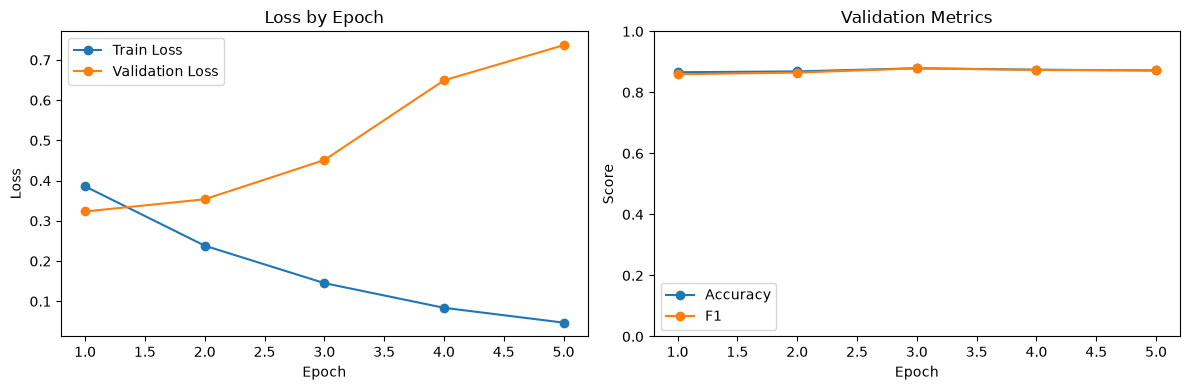

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df['epoch'], history_df['train_loss'], marker='o', label='Train Loss')
axes[0].plot(history_df['epoch'], history_df['val_loss'], marker='o', label='Validation Loss')
axes[0].set(xlabel='Epoch', ylabel='Loss', title='Loss by Epoch')
axes[0].legend()
axes[1].plot(history_df['epoch'], history_df['val_accuracy'], marker='o', label='Accuracy')
axes[1].plot(history_df['epoch'], history_df['val_f1'], marker='o', label='F1')
axes[1].set(xlabel='Epoch', ylabel='Score', title='Validation Metrics', ylim=(0, 1))
axes[1].legend()
plt.tight_layout()
plt.savefig(RESULT_DIR / 'training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

#### 최고 모델 불러오기 및 테스트 평가

In [18]:
loaded_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2, id2label=label_dict,
    label2id={'부정': 0, '긍정': 1}, problem_type='single_label_classification'
)
state_dict = torch.load(BEST_MODEL_PATH, map_location='cpu', weights_only=True)
loaded_model.load_state_dict(state_dict)
loaded_model.to(DEVICE)
loaded_model.eval()
print('최고 모델 로드 완료')

test_metrics, test_logits, test_y = evaluate(loaded_model, test_dataloader, DEVICE)
for name, value in test_metrics.items():
    print(f'{name}: {value:.4f}')

test_probs = F.softmax(torch.tensor(test_logits), dim=1).numpy()
test_pred = np.argmax(test_probs, axis=1)
print('\nClassification Report:')
print(classification_report(test_y, test_pred, target_names=['부정', '긍정'], zero_division=0))
pd.DataFrame([test_metrics]).to_csv(RESULT_DIR / 'test_metrics.csv', index=False)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at klue/bert-base and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


최고 모델 로드 완료


  0%|          | 0/313 [00:00<?, ?it/s]

accuracy: 0.8798
precision: 0.8768
recall: 0.8868
f1: 0.8818
loss: 0.4424

Classification Report:
              precision    recall  f1-score   support

          부정       0.88      0.87      0.88      2473
          긍정       0.88      0.89      0.88      2527

    accuracy                           0.88      5000
   macro avg       0.88      0.88      0.88      5000
weighted avg       0.88      0.88      0.88      5000



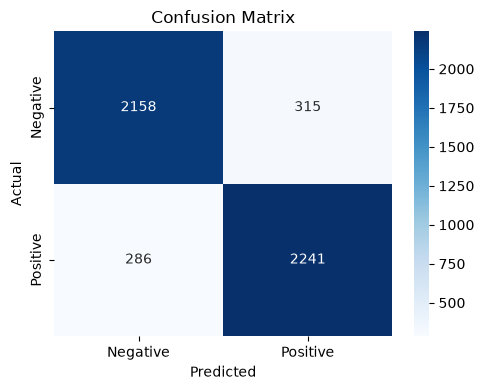

In [19]:
cm = confusion_matrix(test_y, test_pred, labels=[0, 1])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.savefig(RESULT_DIR / 'confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

#### 오답 분석

In [20]:
analysis_df = test[['document', 'label']].copy()
analysis_df['prediction'] = test_pred
analysis_df['negative_prob'] = test_probs[:, 0]
analysis_df['positive_prob'] = test_probs[:, 1]
analysis_df['correct'] = analysis_df['label'] == analysis_df['prediction']
errors = analysis_df[~analysis_df['correct']].copy()
errors['confidence'] = test_probs[np.arange(len(test_probs)), test_pred][~analysis_df['correct'].to_numpy()]
errors = errors.sort_values('confidence', ascending=False)
errors.to_csv(RESULT_DIR / 'error_analysis.csv', index=False, encoding='utf-8-sig')
print('오답 수:', len(errors), '/', len(analysis_df))
display(errors.head(20))

오답 수: 601 / 5000


,document,label,prediction,negative_prob,positive_prob,correct,confidence
785,인상 깊진 않았음.,1,0,0.998848,0.001152,False,0.998848
2750,소재도 신선하고 반전도 좋았으나 너무 현실성이 없다,1,0,0.998451,0.001549,False,0.998451
1612,대대장 중대장 다 쓰레기...,1,0,0.998407,0.001593,False,0.998407
689,운전을 오래해서 관객도 피곤하다. 그러나 사는 데 큰 이유가 있는 게 아니다.,1,0,0.998398,0.001602,False,0.998398
1263,"개인적으론 별3개짜리 영화, 각본,음악,화면연출은 훌륭한듯하나 관객과의 소통부재?",1,0,0.998328,0.001672,False,0.998328
4245,"법집행의 이면에 가려진, 상실된 인간성의 처연한 풍경.. 사형제도에 대한 고찰의기회",0,1,0.001683,0.998317,False,0.998317
1216,완전내취향. 이게 왜 재미없을까?!,1,0,0.998231,0.001769,False,0.998231
2309,최고 찌질이 백건욱~^^ㅋㅋ 작 가님대박 !!! 저런캐릭터 만들기 쉽지않았을텐데~~...,0,1,0.001866,0.998134,False,0.998134
2277,중국영화쓰레기;;라생각하고 조금만 감상하려다가 끝가지다봄ㅋ,1,0,0.998126,0.001874,False,0.998126
367,수준은 떨어지지만 인생을 즐기는게 느껴지는 영화,0,1,0.001891,0.998109,False,0.998109


### **5. 새로운 문장을 직접 입력하여 예측**

In [21]:
pipe = pipeline(
    task='text-classification',
    model=loaded_model,
    tokenizer=tokenizer,
    device=0 if DEVICE.type == 'cuda' else -1,
    truncation=True,
    max_length=MAX_LEN,
    function_to_apply='softmax',
    top_k=None
)
print(pipe('정말 재미있고 감동적인 영화였어요.'))

Device set to use cuda:0


[[{'label': '긍정', 'score': 0.996220052242279}, {'label': '부정', 'score': 0.0037800020072609186}]]


In [22]:
def prediction(text):
    if not isinstance(text, str) or not text.strip():
        raise ValueError('리뷰 문장을 입력해 주세요.')
    results = pipe(text)
    if results and isinstance(results[0], list):
        results = results[0]
    scores = {item['label']: float(item['score']) for item in results}
    predicted = max(scores, key=scores.get)
    print('리뷰:', text)
    print('예측 감정:', predicted)
    print(f'부정 확률: {scores["부정"]:.2%}')
    print(f'긍정 확률: {scores["긍정"]:.2%}')

    return {'text': text, 'prediction': predicted, **scores}

In [23]:
examples = [
    '정말 재미있고 배우들의 연기도 좋았어요.',
    '시간이 아까울 정도로 지루했습니다.',
    '배우 연기는 좋은데 스토리가 너무 별로였어요.',
    '와 진짜 너무 재미없어서 눈물이 나네ㅋㅋ',
    '기대 안 했는데 생각보다 괜찮았어요.'
]
for text in examples:
    prediction(text)
    print('-' * 50)

리뷰: 정말 재미있고 배우들의 연기도 좋았어요.
예측 감정: 긍정
부정 확률: 0.38%
긍정 확률: 99.62%
--------------------------------------------------
리뷰: 시간이 아까울 정도로 지루했습니다.
예측 감정: 부정
부정 확률: 99.94%
긍정 확률: 0.06%
--------------------------------------------------
리뷰: 배우 연기는 좋은데 스토리가 너무 별로였어요.
예측 감정: 부정
부정 확률: 99.89%
긍정 확률: 0.11%
--------------------------------------------------
리뷰: 와 진짜 너무 재미없어서 눈물이 나네ㅋㅋ
예측 감정: 부정
부정 확률: 99.91%
긍정 확률: 0.09%
--------------------------------------------------
리뷰: 기대 안 했는데 생각보다 괜찮았어요.
예측 감정: 긍정
부정 확률: 0.55%
긍정 확률: 99.45%
--------------------------------------------------


In [24]:
my_review = '인생 영화 될 것 같아요ㅠ'
my_result = prediction(my_review)

리뷰: 인생 영화 될 것 같아요ㅠ
예측 감정: 긍정
부정 확률: 0.33%
긍정 확률: 99.67%
